> Notebook-friendly copy of `part-I/1.5-pandas-environmental-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [135]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# Environmental Exercises

**ℹ️ How to use these exercises**

Attempt each from scratch in the empty code cell. Import pandas as `pd` and numpy as `np`, seed any randomness with `default_rng`, and keep units in your column names.

## Exercise 1: Earthquake data analysis

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/usgs-2014-south-napa-earthquake.jpg" alt="A dirt track through a vineyard, broken along its length by a continuous ridge of pushed-up soil following the fault trace" width="800">

<em>Surface rupture from the magnitude 6.0 South Napa earthquake of 24 August 2014 — the kind of event a row in this catalog stands for. The continuous "mole track" running parallel to the strike of the fault indicates some east–west compression on top of the <a href="https://www.usgs.gov/faqs/what-fault-and-what-are-different-types">right-lateral faulting</a>; taken near Buhman Road. Photo <a href="https://www.usgs.gov/media/images/2014-south-napa-ca-m6-earthquake-august-24-6">USGS</a>, public domain.</em>


This exercise reviews the `pandas` fundamentals of this subchapter on one real catalog, covering how to

* open csv files
* manipulate dataframe indexes
* parse date columns
* examine basic dataframe statistics
* manipulate text columns and extract values
* plot dataframe contents using
  * bar charts
  * histograms
  * scatter plots

The data is a snapshot of the [USGS Earthquakes Database](https://earthquake.usgs.gov/earthquakes/search/): every event recorded worldwide in 2014, 120 108 rows.

You do not need to download the file yourself. The pre-supplied cell below fetches and caches it with the help of [pooch](https://www.fatiando.org/pooch/latest/) — there is no need to read pooch's documentation unless you want to — and stores the path to the file in the variable `datafile`.

In [136]:
# Pre-supplied: download and cache the earthquake data.
import pooch

datafile = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/usgs_earthquakes_2014.csv",
    known_hash="sha256:84d455fb96dc8f782fba4b5fbe56cb8970cab678f07c766fcba1b1c4674de1b1",
    fname="usgs_earthquakes_2014.csv",
    path=pooch.os_cache("mlees"),
)

**ℹ️ Beyond this subchapter**

The tools below were not demonstrated in 1.5's lecture. Each question links its documentation where
it is needed; they are collected here so you know when you are being asked to read a new page rather
than to recall one:

- [`nlargest`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.nlargest.html) — Q5
- [pandas' text data functions](https://pandas.pydata.org/pandas-docs/stable/user_guide/text.html), and [`Series.str.split`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.str.split.html) in particular — Q6
- [`unique`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.unique.html) — Q7
- [`count`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.count.html) and [`value_counts`](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html) — Q9

The scatter plot and colorbar in Q11 are the ones from 1.4.6. Everything else the questions ask for
is from this subchapter's lecture: `read_csv` with date-parsed columns, `set_index`, `.head()`,
`.info()`, `.describe()`, boolean filtering, `.index` and `.values`, `kind="bar"`, `kind="hist"`, and
a logarithmic count axis.

**Q1) First, import `numpy`, `pandas` and `matplotlib`, and — optionally — set the display options.**

Hint: display options are documented [at this link](https://pandas.pydata.org/pandas-docs/stable/user_guide/options.html).

In [137]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

**Q2) Use pandas' `read_csv` function directly on `datafile` to open it as a `DataFrame`.**

Display the first few rows with `.head()`, and the column names, dtypes and non-null counts with
`.info()`. Check these tutorials if you have doubts about what the two functions do:
[`.head()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.head.html)
and
[`.info()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.info.html?highlight=info#pandas.DataFrame.info).

`.info()` will show you that the two date columns, `time` and `updated`, came in as plain strings
rather than as dates. They were not parsed automatically. What can you do about that?

In [138]:
df = pd.read_csv(datafile)
print(df.head())
print(df.info())

# Answer: we can convert them

# Open the file as a pandas DataFrame, then display the first few rows and the DataFrame info

                      time   latitude  longitude  depth   mag magType  nst  \
0  2014-01-31 23:53:37.000  60.252000  -152.7081  90.20  1.10      ml  NaN   
1  2014-01-31 23:48:35.452  37.070300  -115.1309   0.00  1.33      ml  4.0   
2  2014-01-31 23:47:24.000  64.671700  -149.2528   7.10  1.30      ml  NaN   
3  2014-01-31 23:30:54.000  63.188700  -148.9575  96.50  0.80      ml  NaN   
4  2014-01-31 23:30:52.210  32.616833  -115.6925  10.59  1.34      ml  6.0   

      gap     dmin     rms net          id                   updated  \
0     NaN      NaN  0.2900  ak  ak11155107  2014-02-05T19:34:41.515Z   
1  171.43  0.34200  0.0247  nn  nn00436847  2014-02-01T01:35:09.000Z   
2     NaN      NaN  1.0000  ak  ak11151142  2014-02-01T00:03:53.010Z   
3     NaN      NaN  1.0700  ak  ak11151135  2014-01-31T23:41:25.007Z   
4  285.00  0.04321  0.2000  ci  ci37171541  2014-02-01T00:13:20.107Z   

                               place        type  
0  26km S of Redoubt Volcano, Alaska  earthquak

**Q3) Re-read the data in such a way that both date columns are identified as dates and the earthquake ID is used as the index.**

Check with `.head()` and `.info()` that it worked: `time` and `updated` should now be
`datetime64` columns, and `id` should be the index rather than a column.

Hint: the documentation for `read_csv` is [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html?highlight=read_csv).

In [139]:
df = pd.read_csv(datafile, parse_dates=["time", "updated"], index_col="id")

# parse_dates takes the list of columns to convert to datetimes.
# index_col takes the column to use as the index (here, the earthquake ID).

print(df.head())
print(df.info())

                              time   latitude  longitude  depth   mag magType  \
id                                                                              
ak11155107 2014-01-31 23:53:37.000  60.252000  -152.7081  90.20  1.10      ml   
nn00436847 2014-01-31 23:48:35.452  37.070300  -115.1309   0.00  1.33      ml   
ak11151142 2014-01-31 23:47:24.000  64.671700  -149.2528   7.10  1.30      ml   
ak11151135 2014-01-31 23:30:54.000  63.188700  -148.9575  96.50  0.80      ml   
ci37171541 2014-01-31 23:30:52.210  32.616833  -115.6925  10.59  1.34      ml   

            nst     gap     dmin     rms net                          updated  \
id                                                                              
ak11155107  NaN     NaN      NaN  0.2900  ak 2014-02-05 19:34:41.515000+00:00   
nn00436847  4.0  171.43  0.34200  0.0247  nn        2014-02-01 01:35:09+00:00   
ak11151142  NaN     NaN      NaN  1.0000  ak 2014-02-01 00:03:53.010000+00:00   
ak11151135  NaN     NaN    

**Q4) Use `describe` to get the basic statistics of all the columns.**

Hint: the documentation of `describe` is [at this link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html).

In [140]:
df.describe(include="all")

# describe() summarises a DataFrame with a few statistics per column.
# By default it only covers the numeric columns, so to get all the columns you need the include parameter "all"

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,net,updated,place,type
count,120108,120108.000000,120108.000000,120107.000000,120065.000000,120065,59688.000000,94935.000000,85682.000000,119716.000000,120108,120108,120108,120108
unique,NaN,NaN,NaN,NaN,NaN,18,NaN,NaN,NaN,NaN,14,NaN,45395,11
top,NaN,NaN,NaN,NaN,NaN,ml,NaN,NaN,NaN,NaN,ak,NaN,"10km E of Mammoth Lakes, California",earthquake
freq,NaN,NaN,NaN,NaN,NaN,57608,NaN,NaN,NaN,NaN,31851,NaN,2201,118398
mean,2014-07-05 09:10:37.116720128,38.399579,-99.961402,28.375029,1.793958,NaN,17.878284,124.048978,0.893198,0.358174,NaN,2014-08-04 04:22:28.357678080+00:00,NaN,NaN
min,2014-01-01 00:01:16.610000,-73.462000,-179.998900,-9.900000,-0.970000,NaN,0.000000,9.000000,0.000000,0.000000,NaN,2014-01-01 00:38:24.983000+00:00,NaN,NaN
25%,2014-04-08 03:43:10.768999936,34.228917,-147.742025,4.100000,0.820000,NaN,8.000000,74.000000,0.020760,0.070000,NaN,2014-04-30 21:18:25+00:00,NaN,NaN
50%,2014-07-07 10:44:06.035000064,38.805300,-120.832000,9.200000,1.400000,NaN,14.000000,107.000000,0.073670,0.200000,NaN,2014-08-06 21:06:23.051500032+00:00,NaN,NaN
75%,2014-09-30 23:36:40.595000064,53.889500,-116.068100,22.880000,2.400000,NaN,22.000000,155.000000,0.447000,0.590000,NaN,2014-10-31 19:05:46.865999872+00:00,NaN,NaN
max,2014-12-31 23:54:33.900000,86.651400,179.998000,697.360000,8.200000,NaN,365.000000,356.400000,64.498000,8.460000,NaN,2015-08-21 00:06:53.450000+00:00,NaN,NaN


**Q5) Use `nlargest` to get the top 20 earthquakes by magnitude.**

Hint: the documentation of `nlargest` is [at this link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.nlargest.html).

In [141]:
df.nlargest(20, "mag")

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,net,updated,place,type
id,,,,,,,,,,,,,,
usc000nzvd,2014-04-01 23:46:47.260,-19.6097,-70.7691,25.00,8.2,mww,NaN,23.0,0.609,0.66,us,2015-07-30 16:24:51.223000+00:00,"94km NW of Iquique, Chile",earthquake
usc000rki5,2014-06-23 20:53:09.700,51.8486,178.7352,109.00,7.9,mww,NaN,22.0,0.133,0.71,us,2015-04-18 21:54:08.699000+00:00,"19km SE of Little Sitkin Island, Alaska",earthquake
usc000p27i,2014-04-03 02:43:13.110,-20.5709,-70.4931,22.40,7.7,mww,NaN,44.0,1.029,0.82,us,2015-06-06 07:31:05.755000+00:00,"53km SW of Iquique, Chile",earthquake
usc000phx5,2014-04-12 20:14:39.300,-11.2701,162.1481,22.56,7.6,mww,NaN,13.0,2.828,0.71,us,2015-04-18 21:54:27.398000+00:00,"93km SSE of Kirakira, Solomon Islands",earthquake
usb000pr89,2014-04-19 13:28:00.810,-6.7547,155.0241,43.37,7.5,mww,NaN,16.0,3.820,1.25,us,2015-04-18 21:54:18.633000+00:00,"70km SW of Panguna, Papua New Guinea",earthquake
usc000piqj,2014-04-13 12:36:19.230,-11.4633,162.0511,39.00,7.4,mww,NaN,17.0,2.885,1.00,us,2015-08-13 19:29:13.018000+00:00,"112km S of Kirakira, Solomon Islands",earthquake
usb000slwn,2014-10-14 03:51:34.460,12.5262,-88.1225,40.00,7.3,mww,NaN,18.0,1.078,0.70,us,2015-08-13 19:35:02.679000+00:00,"74km S of Intipuca, El Salvador",earthquake
usb000pq41,2014-04-18 14:27:24.920,17.3970,-100.9723,24.00,7.2,mww,NaN,46.0,2.250,1.20,us,2015-08-13 19:30:39.599000+00:00,"33km ESE of Petatlan, Mexico",earthquake
usc000pft9,2014-04-11 07:07:23.130,-6.5858,155.0485,60.53,7.1,mww,NaN,21.0,3.729,0.88,us,2014-07-01 02:37:56+00:00,"56km WSW of Panguna, Papua New Guinea",earthquake


**Q6) Extract the state or country using pandas' text data functions, and add it as a new column to the `DataFrame`.**

Examine the column titled `place`: it holds strings like `"26km S of Redoubt Volcano, Alaska"`, so
it carries both the local description and the state or country. Pull the second part out and store
it in a new column called `country`.

Hint 1: the documentation for pandas' text data functions is [here](https://pandas.pydata.org/pandas-docs/stable/text.html).

Hint 2: you will use `.split()` to extract the country names. The documentation of this function
can be found [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.str.split.html?highlight=split#pandas.Series.str.split).

In [142]:
separate = df["place"].str.split(", ")

print(separate)

df["place"] = separate.str[0]
df["country"] = separate.str[-1]

df[["place", "country"]].head()

# df["place"].str.split(", ") splits each string wherever there is a comma followed by a space.
# "26km S of Redoubt Volcano, Alaska" becomes the list ["26km S of Redoubt Volcano", "Alaska"].
# .str[-1] takes the last element of each list. Index -1 means “the last one”, so "Alaska" is kept.

id
ak11155107    [26km S of Redoubt Volcano, Alaska]
nn00436847              [32km S of Alamo, Nevada]
ak11151142     [12km NNW of North Nenana, Alaska]
ak11151135           [22km S of Cantwell, Alaska]
ci37171541         [10km WNW of Progreso, Mexico]
                             ...                 
ak11453391            [29km SW of Valdez, Alaska]
ak11453395     [102km SSE of Old Iliamna, Alaska]
nc72358451          [9km WNW of Cobb, California]
ak11453390             [57km NW of Ester, Alaska]
ak11453389          [78km WSW of Cordova, Alaska]
Name: place, Length: 120108, dtype: object


,place,country
id,,
ak11155107,26km S of Redoubt Volcano,Alaska
nn00436847,32km S of Alamo,Nevada
ak11151142,12km NNW of North Nenana,Alaska
ak11151135,22km S of Cantwell,Alaska
ci37171541,10km WNW of Progreso,Mexico


**Q7) Display each unique value from the new `country` column.**

Hint: you may use the `unique` function documented [at this link](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.unique.html).

You should see an array of a couple of hundred country and state names. A plain split leaves the
space that followed the comma, so they come out as `array([' Alaska', ' Nevada', ...])` — worth
removing before you use them as labels.

In [143]:
df["country"].unique()

array(['Alaska', 'Nevada', 'Mexico', 'California', 'Papua New Guinea',
       'New Zealand', 'Missouri', 'South of the Fiji Islands', 'Montana',
       'British Virgin Islands', 'Washington', 'Oregon', 'Canada', 'Fiji',
       'Wyoming', 'Antarctica', 'Chile', 'Utah', 'Indonesia',
       'Solomon Islands', 'Micronesia', 'Oklahoma', 'Hawaii', 'Russia',
       'Arizona', 'Philippines', 'Bolivia', 'Greece', 'Japan',
       'Puerto Rico', 'Iran', 'Tonga', 'Wallis and Futuna', 'Colorado',
       'Guam', 'CA', 'Carlsberg Ridge', 'Idaho', 'Pakistan',
       'Off the west coast of northern Sumatra', 'Burma', 'China', 'Peru',
       'Off the east coast of the North Island of New Zealand',
       'Costa Rica', 'Reykjanes Ridge', 'East Timor',
       'Central East Pacific Rise', 'Mid-Indian Ridge', 'Japan region',
       'Northern Mariana Islands', 'El Salvador', 'Samoa',
       'Northern Mid-Atlantic Ridge', 'Taiwan', 'Arkansas',
       'South Sandwich Islands', 'Colombia', 'Dominican Republic',

**Q8) Create a filtered dataset that only has earthquakes larger than magnitude 4.**

Hint: print the table to see the name of the column containing the earthquake magnitude.

Check out this [link](https://www.geeksforgeeks.org/ways-to-filter-pandas-dataframe-by-column-values/)
to find examples of filtering by column values.

In [144]:
print(df)
df.columns                    # to see the name of the columns df holds
df_big = df[df["mag"] > 4]    # df["mag"] > 4 compares every magnitude to 4 and gives a column of True/False values, one per row.
                              # Putting that inside df[...]
print(df_big)

                              time   latitude   longitude   depth   mag  \
id                                                                        
ak11155107 2014-01-31 23:53:37.000  60.252000 -152.708100   90.20  1.10   
nn00436847 2014-01-31 23:48:35.452  37.070300 -115.130900    0.00  1.33   
ak11151142 2014-01-31 23:47:24.000  64.671700 -149.252800    7.10  1.30   
ak11151135 2014-01-31 23:30:54.000  63.188700 -148.957500   96.50  0.80   
ci37171541 2014-01-31 23:30:52.210  32.616833 -115.692500   10.59  1.34   
...                            ...        ...         ...     ...   ...   
ak11453391 2014-12-01 00:10:16.000  60.963900 -146.762900   14.80  3.80   
ak11453395 2014-12-01 00:09:39.000  58.869100 -154.415900  108.40  2.40   
nc72358451 2014-12-01 00:09:25.350  38.843498 -122.825836    2.37  0.43   
ak11453390 2014-12-01 00:05:54.000  65.152100 -148.992000    9.50  0.40   
ak11453389 2014-12-01 00:04:05.000  60.227200 -147.024500    2.50  1.60   

           magType  nst 

**Q9) Using the filtered dataset (magnitude > 4), count the number of earthquakes whose magnitudes are above 4 [Num 1], and count the number of earthquakes in each country or state [Num 2]. Make a bar chart of Num 2 for the top 5 locations with the most earthquakes.**

Hint 1: to get Num 1, pandas has a `count` function documented
[at this link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.count.html).

Hint 2: check out the
[`value_counts`](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html)
function to get Num 2.

Then convert the first five rows of Num 2 into a `DataFrame` with two columns, `country` (text)
and `earthquake_num` (number), and recreate the bar chart below.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-top5-bar.png" alt="A bar chart of the number of magnitude-above-4 earthquakes in the five countries with the most of them" width="700">

<em>The five locations with the most magnitude-above-4 events in 2014.</em>

16371
country
Indonesia            1911
Papua New Guinea     1290
Japan                1114
Chile                 995
New Zealand           729
                     ... 
South of Tasmania       1
Eastern Greenland       1
Kosovo                  1
Saint Lucia             1
Arizona                 1
Name: count, Length: 262, dtype: int64
country
Indonesia           1911
Papua New Guinea    1290
Japan               1114
Chile                995
New Zealand          729
Name: count, dtype: int64


<Axes: title={'center': 'Top 5 countries with the biggest earthquakes (mag > 4)'}, xlabel='Country/State', ylabel='Number of earthquakes'>

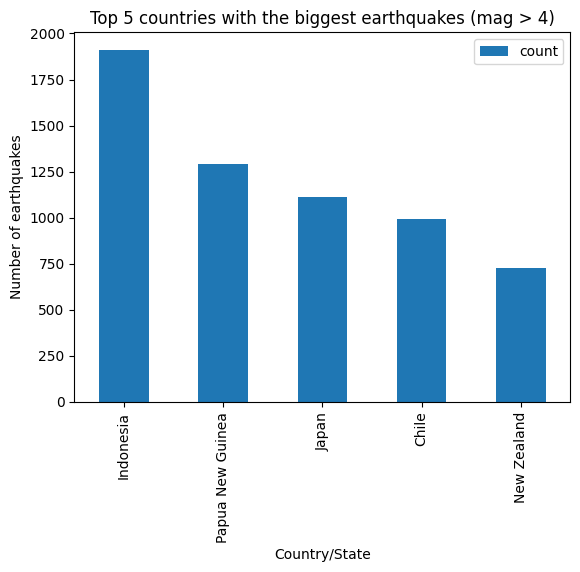

In [145]:
# num1 = df_big.count() -> If you call count() on the whole DataFrame instead, you get one count per column.
num1 = df_big["mag"].count()
print(num1)

num2 = df_big["country"].value_counts()
# value_counts() counts how often each value appears and sorts the result from most to least common.
# The top 5 are therefore the first five rows
print(num2)

top_5 = num2[:5]
top_5.columns = ["country", "earthquake_num"]
print(top_5)

top_5.plot(x="country", y="earthquake_num", kind="bar", title="Top 5 countries with the biggest earthquakes (mag > 4)",
           xlabel="Country/State", ylabel="Number of earthquakes", legend=True)

**Q10) Make a histogram for the distribution of the earthquakes' magnitudes.**

Hint: pandas has a histogram function documented
[at this link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.hist.html) and
matplotlib has one documented
[at this link](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.hist.html).

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-magnitude-hist.png" alt="A histogram of earthquake magnitude with a dashed grid" width="700">

<em>The distribution of magnitude across the whole catalog.</em>


Then redraw it with a logarithmic scale on the y-axis, which brings the rare large events into
view alongside the many small ones. Hint: here you can find a
[tutorial](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.yscale.html) for how to
change an axis scale.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-magnitude-hist-log.png" alt="The same histogram of earthquake magnitude with a logarithmic y-axis" width="700">

<em>The same histogram with a logarithmic count axis.</em>


Finally, make one histogram for the filtered dataset and one for the unfiltered dataset, side by
side.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-hist-filtered-unfiltered.png" alt="Two histograms of earthquake magnitude side by side, one for events above magnitude 4 and one for the whole catalog" width="100%">

<em>The filtered and unfiltered magnitude distributions, drawn on their own count axes.</em>

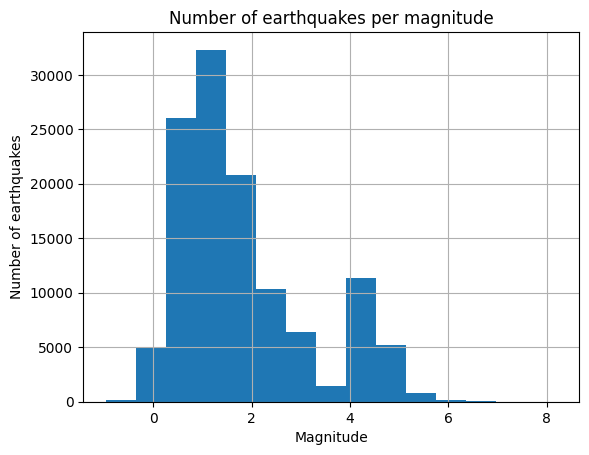

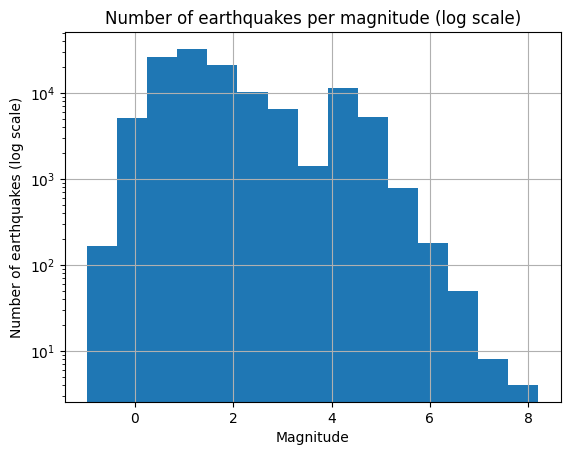

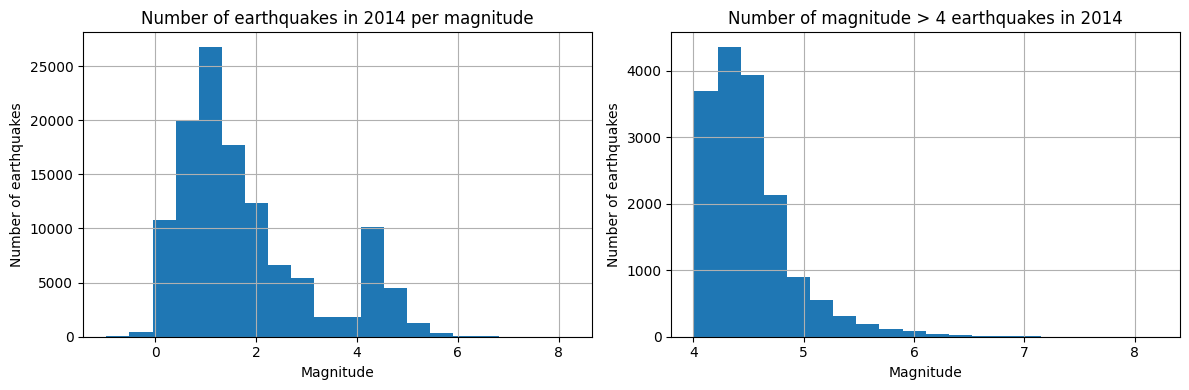

In [146]:
# 1

ax = df["mag"].hist(bins=15)
ax.set_xlabel("Magnitude")
ax.set_ylabel("Number of earthquakes")
ax.set_title("Number of earthquakes per magnitude")
plt.show()


# 2

ax = df["mag"].hist(bins=15)
ax.set_yscale("log")                # ax.set_yscale("log") is equivalent to plt.yscale("log")
ax.set_xlabel("Magnitude")
ax.set_ylabel("Number of earthquakes (log scale)")
ax.set_title("Number of earthquakes per magnitude (log scale)")
# also possible to add log=True in the hist function
plt.show()


# 3

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["mag"].hist(bins=20, ax=axes[0])
axes[0].set_title("Number of earthquakes in 2014 per magnitude")
axes[0].set_xlabel("Magnitude")
axes[0].set_ylabel("Number of earthquakes")

df_big["mag"].hist(bins=20, ax=axes[1])
axes[1].set_title("Number of magnitude > 4 earthquakes in 2014")
axes[1].set_xlabel("Magnitude")
axes[1].set_ylabel("Number of earthquakes")

plt.tight_layout()
plt.show()

**Q11) Visualise the locations of earthquakes by making a scatterplot of their latitude and longitude.**

Make a figure with two panels: one for the filtered dataset and one for the unfiltered one, with
the points coloured by magnitude on a shared colour range.

Hint: consider reading the documentation for
[`plt.scatter`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) to make
the scatter plot and that of
[`plt.colorbar`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.colorbar.html) to
colour the points by magnitude. Pass the same `vmin` and `vmax` to both scatter calls, so that a
colour stands for the same magnitude in both panels.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-quake-scatter.png" alt="Two scatter plots of earthquake longitude against latitude coloured by magnitude, one filtered to magnitude above 4 and one unfiltered" width="100%">

<em>Every event in the catalog placed by longitude and latitude, filtered and unfiltered.</em>

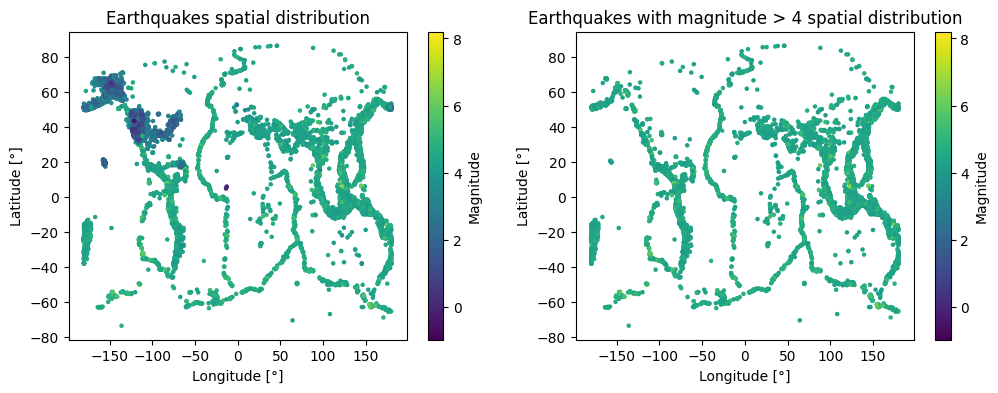

In [149]:
vmin, vmax = df["mag"].min(), df["mag"].max()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sc0 = axes[0].scatter(df["longitude"], df["latitude"], c=df["mag"],   # c gives with what we want to color the points
                s=5, vmin=vmin, vmax=vmax)        # s gives size of the point, vmin and vmax the magnitude range
axes[0].set_xlabel("Longitude [°]")
axes[0].set_ylabel("Latitude [°]")
axes[0].set_title("Earthquakes spatial distribution")

sc1 = axes[1].scatter(df_big["longitude"], df_big["latitude"], c=df_big["mag"],
                s=5, vmin=vmin, vmax=vmax)
axes[1].set_xlabel("Longitude [°]")
axes[1].set_ylabel("Latitude [°]")
axes[1].set_title("Earthquakes with magnitude > 4 spatial distribution")

fig.colorbar(sc0, ax=axes[0], label="Magnitude")     # sc says what is described by colorbar
                                                  # here, both represent same unit and color so 1 colorbar is enough
fig.colorbar(sc1, ax=axes[1], label="Magnitude")
plt.show()


# The difference in the filtered dataset is all the small earthquakes situated mostly on the East Coast and South
# of USA are not represented anymore


Do you notice a difference between the filtered and unfiltered datasets?